# 08 · Machine Learning Prediction

**IBM Applied Data Science Capstone · SpaceX Falcon 9 first-stage landing prediction**  
Author: Martim Ramos

Standardize the data, split train/test, tune Logistic Regression, SVM, Decision Tree and KNN with GridSearchCV (cv = 10), and find the best model. Inputs: `data/dataset_part_2.csv`, `data/dataset_part_3.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV, RepeatedStratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

def plot_confusion_matrix(y, y_predict, title=""):
    cm = confusion_matrix(y, y_predict)
    ax = plt.subplot()
    sns.heatmap(cm, annot=True, ax=ax, fmt="d", cmap="Blues")
    ax.set_xlabel('Predicted labels'); ax.set_ylabel('True labels')
    ax.set_title('Confusion Matrix ' + title)
    ax.xaxis.set_ticklabels(['did not land', 'land']); ax.yaxis.set_ticklabels(['did not land', 'landed'])
    plt.show()

In [2]:
data = pd.read_csv("data/dataset_part_2.csv")
X = pd.read_csv("data/dataset_part_3.csv")
X.shape

(90, 80)

## Task 1: Create the target array Y

In [3]:
Y = data['Class'].to_numpy()

## Task 2: Standardize the data

In [4]:
transform = preprocessing.StandardScaler()
X = transform.fit(X).transform(X)

## Task 3: Train / test split (80/20, random_state = 2)

In [5]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
Y_test.shape

(18,)

## Task 4–5: Logistic Regression

tuned hyperparameters :(best parameters)  {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}
accuracy : 0.8214285714285714
test accuracy : 0.8333333333333334


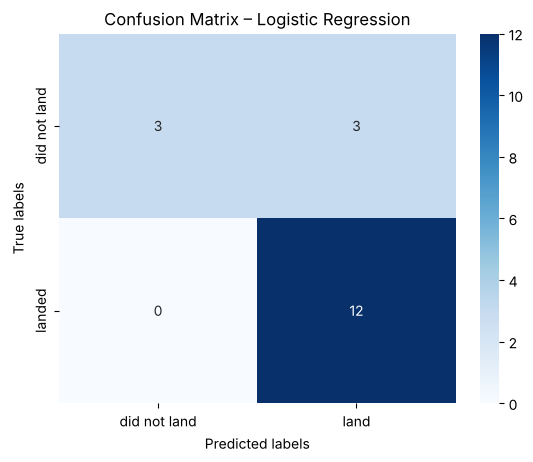

In [6]:
parameters = {'C': [0.01, 0.1, 1], 'penalty': ['l2'], 'solver': ['lbfgs']}
logreg_cv = GridSearchCV(LogisticRegression(), parameters, cv=10).fit(X_train, Y_train)
print("tuned hyperparameters :(best parameters) ", logreg_cv.best_params_)
print("accuracy :", logreg_cv.best_score_)
print("test accuracy :", logreg_cv.score(X_test, Y_test))
plot_confusion_matrix(Y_test, logreg_cv.predict(X_test), "– Logistic Regression")

## Task 6–7: Support Vector Machine

tuned hyperparameters :(best parameters)  {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}
accuracy : 0.8482142857142858
test accuracy : 0.8333333333333334


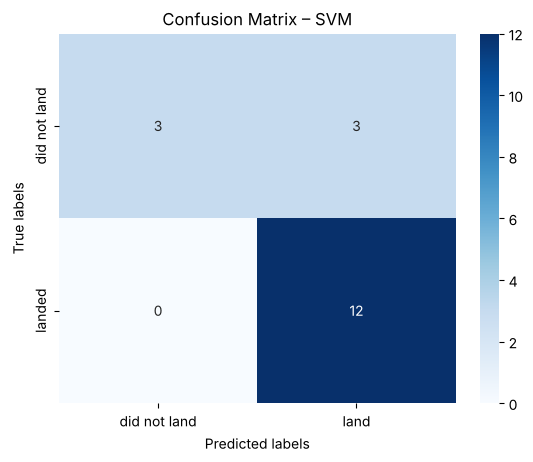

In [7]:
parameters = {'kernel': ('linear', 'rbf', 'poly', 'rbf', 'sigmoid'), 'C': np.logspace(-3, 3, 5), 'gamma': np.logspace(-3, 3, 5)}
svm_cv = GridSearchCV(SVC(), parameters, cv=10).fit(X_train, Y_train)
print("tuned hyperparameters :(best parameters) ", svm_cv.best_params_)
print("accuracy :", svm_cv.best_score_)
print("test accuracy :", svm_cv.score(X_test, Y_test))
plot_confusion_matrix(Y_test, svm_cv.predict(X_test), "– SVM")

## Task 8–9: Decision Tree

tuned hyperparameters :(best parameters)  {'criterion': 'gini', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'best'}
accuracy : 0.8053571428571429
test accuracy : 0.7222222222222222


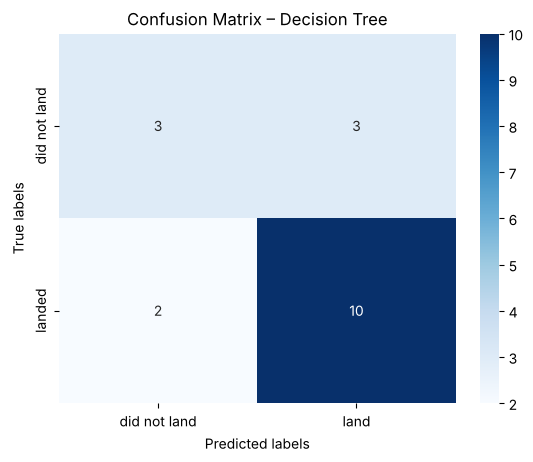

In [8]:
parameters = {'criterion': ['gini', 'entropy'], 'splitter': ['best', 'random'], 'max_depth': [2 * n for n in range(1, 10)],
              'max_features': ['sqrt'], 'min_samples_leaf': [1, 2, 4], 'min_samples_split': [2, 5, 10]}
tree_cv = GridSearchCV(DecisionTreeClassifier(random_state=12), parameters, cv=10).fit(X_train, Y_train)
print("tuned hyperparameters :(best parameters) ", tree_cv.best_params_)
print("accuracy :", tree_cv.best_score_)
print("test accuracy :", tree_cv.score(X_test, Y_test))
plot_confusion_matrix(Y_test, tree_cv.predict(X_test), "– Decision Tree")

## Task 10–11: K Nearest Neighbors

tuned hyperparameters :(best parameters)  {'algorithm': 'auto', 'n_neighbors': 6, 'p': 1}
accuracy : 0.8339285714285714
test accuracy : 0.8333333333333334


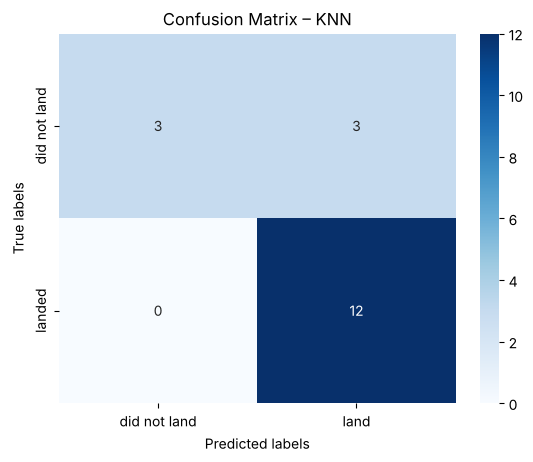

In [9]:
parameters = {'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10], 'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'], 'p': [1, 2]}
knn_cv = GridSearchCV(KNeighborsClassifier(), parameters, cv=10).fit(X_train, Y_train)
print("tuned hyperparameters :(best parameters) ", knn_cv.best_params_)
print("accuracy :", knn_cv.best_score_)
print("test accuracy :", knn_cv.score(X_test, Y_test))
plot_confusion_matrix(Y_test, knn_cv.predict(X_test), "– KNN")

## Task 12: Find the method that performs best

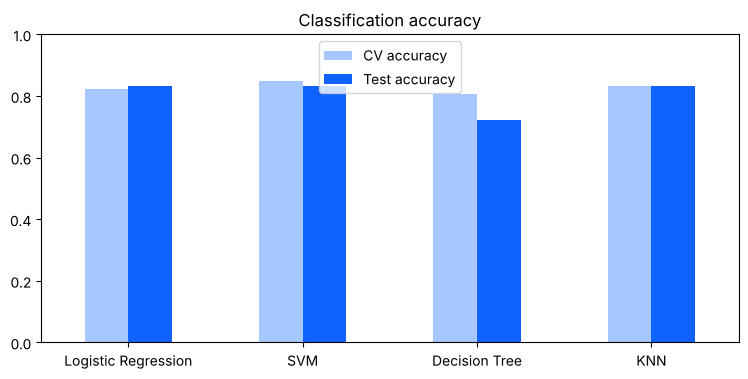

,CV accuracy,Test accuracy
Logistic Regression,0.8214,0.8333
SVM,0.8482,0.8333
Decision Tree,0.8054,0.7222
KNN,0.8339,0.8333


In [10]:
models = {'Logistic Regression': logreg_cv, 'SVM': svm_cv, 'Decision Tree': tree_cv, 'KNN': knn_cv}
results = pd.DataFrame({'CV accuracy': {k: m.best_score_ for k, m in models.items()},
                        'Test accuracy': {k: m.score(X_test, Y_test) for k, m in models.items()}})
results.plot(kind='bar', figsize=(9, 4), color=['#A6C8FF', '#0F62FE'], rot=0, ylim=(0, 1), title='Classification accuracy')
plt.show()
results.round(4)

In [11]:
best = results.sort_values(['Test accuracy', 'CV accuracy'], ascending=False).index[0]
print('Best model:', best, models[best].best_params_)

Best model: SVM {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}


## Extra: robustness check with repeated stratified CV (5-fold × 20)

In [12]:
X_raw = pd.read_csv("data/dataset_part_3.csv")
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=0)
rep = {}
for k, m in models.items():
    s = cross_val_score(make_pipeline(preprocessing.StandardScaler(), m.best_estimator_), X_raw, Y, cv=cv)
    rep[k] = (round(s.mean(), 4), round(s.std(), 4))
pd.DataFrame(rep, index=['mean accuracy', 'std']).T

,mean accuracy,std
Logistic Regression,0.8144,0.0783
SVM,0.8478,0.0731
Decision Tree,0.7700,0.1133
KNN,0.8311,0.0820


SVM, Logistic Regression and KNN all reach **83.3%** test accuracy (15 of 18). SVM has the best cross-validation accuracy and stays best under repeated CV, so it is selected as the best model.